# Практика 3: сравнение методов декомпозиции на ряде со сложной сезонностью

**Цель:** на одном ряду применить классическую декомпозицию, STL и MSTL и показать, как выбор метода влияет на компоненты и на интерпретацию.

**Данные.** Ряд генерируется генератором из ЛР 1 (`generate_time_series`) с режимом `seasonality="two"`. В ЛР 1 шаг был 5 минут, и периоды были 12 и 72 точки. Формулы генератора те же, поэтому здесь меняются только константы: шаг 1 час, периоды **24** (сутки) и **168** (неделя). Сверху добавляем то, чего в генераторе нет:

- выходные ниже будней на 20 (делает недельный профиль не синусоидой, как у реальных почасовых данных, например электропотребления);
- небольшой сдвиг уровня +10 с 9-й недели;
- 6 выбросов (параметр `outliers=6` самого генератора).

Ряд синтетический, поэтому истинные компоненты известны, и качество методов можно измерить напрямую.

## 0. Импорт и генератор из ЛР 1

In [ ]:
import os
from datetime import datetime, date, time, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100

# ---- генератор из ЛР 1 (без сохранения в файлы) ----
STEP = timedelta(minutes=5)
VARIANCE_MODES = ("const", "grow", "decay")
TREND_MODES = ("none", "fast_up", "slow_up", "fast_down", "slow_down")
EXTRA_TREND_MODES = ("exp", "poly", "log")
SEASONALITY_MODES = ("none", "one", "two")
PERIOD_1H = 12
PERIOD_6H = 72
TREND_DELTA = {"fast_up": 150.0, "slow_up": 30.0, "fast_down": -150.0, "slow_down": -30.0}


def make_timestamps(n_points, start=None):
    if start is None:
        start = datetime.combine(date.today(), time.min)
    return [start + i * STEP for i in range(n_points)]


def make_variance(mode, n_points):
    t = np.linspace(0.0, 1.0, n_points)
    if mode == "const":
        return np.ones(n_points)
    if mode == "grow":
        return 0.5 + 4.5 * t
    if mode == "decay":
        return 5.0 - 4.5 * t
    raise ValueError(f"Неизвестный режим дисперсии: {mode}")


def make_trend(mode, n_points):
    t = np.linspace(0.0, 1.0, n_points)
    if mode == "none":
        return np.zeros(n_points)
    if mode in TREND_DELTA:
        return TREND_DELTA[mode] * t
    if mode == "exp":
        return 100.0 * (np.exp(3.0 * t) - 1.0) / (np.exp(3.0) - 1.0)
    if mode == "poly":
        return 100.0 * (t ** 3 - 1.5 * t ** 2 + t)
    if mode == "log":
        return 100.0 * np.log1p(20.0 * t) / np.log1p(20.0)
    raise ValueError(f"Неизвестный режим тренда: {mode}")


def make_seasonality(mode, n_points):
    i = np.arange(n_points)
    if mode == "none":
        return np.zeros(n_points)
    if mode == "one":
        return 10.0 * np.sin(2 * np.pi * i / PERIOD_1H)
    if mode == "two":
        return (10.0 * np.sin(2 * np.pi * i / PERIOD_1H)
                + 20.0 * np.sin(2 * np.pi * i / PERIOD_6H))
    raise ValueError(f"Неизвестный режим сезонности: {mode}")


def generate_time_series(n_points=1000, variance="random", trend="random",
                         seasonality="random", base=100.0, noise_std=1.0, seed=None,
                         outliers=0, missing=0.0, start=None):
    rng = np.random.default_rng(seed)
    if variance == "random":
        variance = str(rng.choice(VARIANCE_MODES))
    if trend == "random":
        trend = str(rng.choice(TREND_MODES))
    if seasonality == "random":
        seasonality = str(rng.choice(SEASONALITY_MODES))

    timestamps = make_timestamps(n_points, start)
    noise = rng.normal(0.0, noise_std, n_points) * make_variance(variance, n_points)
    values = base + make_trend(trend, n_points) + make_seasonality(seasonality, n_points) + noise

    outlier_idx = []
    if outliers > 0:
        outlier_idx = rng.choice(n_points, size=min(outliers, n_points), replace=False)
        scale = np.std(values) * 3
        values[outlier_idx] += rng.choice([-1, 1], size=len(outlier_idx)) * scale
        outlier_idx = sorted(int(k) for k in outlier_idx)

    missing_idx = []
    if missing > 0:
        k = int(round(n_points * missing))
        missing_idx = rng.choice(n_points, size=k, replace=False)
        values[missing_idx] = np.nan
        missing_idx = sorted(int(k) for k in missing_idx)

    params = {"n_points": n_points, "step_minutes": 5,
              "start": timestamps[0].strftime("%Y-%m-%d %H:%M:%S"),
              "variance": variance, "trend": trend, "seasonality": seasonality,
              "base": base, "noise_std": noise_std, "seed": seed,
              "outliers": outlier_idx, "missing_count": len(missing_idx)}
    return timestamps, values, params

In [ ]:
try:
    import statsmodels
    from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
    from statsmodels.tsa.stattools import acf
except ImportError as e:
    raise ImportError("Нужен statsmodels >= 0.14. Выполните в ячейке:  %pip install -U statsmodels") from e
print("statsmodels", statsmodels.__version__)

statsmodels 0.15.0


## 1. Генерация ряда

Меняем константы генератора под часовой шаг. Функции `make_timestamps` и `make_seasonality` читают их как глобальные переменные, поэтому достаточно переопределить значения.

In [ ]:
STEP = timedelta(hours=1)    # было 5 минут
PERIOD_1H = 24               # суточный период (было 12 точек)
PERIOD_6H = 168              # недельный период (было 72 точки)

N_WEEKS = 12
N = N_WEEKS * 168            # 12 * 168 = 2016 часов
START = datetime(2026, 9, 7) # понедельник 00:00
NOISE_STD = 3.0

ts, vals, params = generate_time_series(
    n_points=N, variance="const", trend="slow_up", seasonality="two",
    base=100.0, noise_std=NOISE_STD, seed=7, outliers=6, start=START)
print(params)

idx = pd.DatetimeIndex(ts, freq="h")
WEEKEND = -20.0                       # Сб/Вс ниже на 20
SHIFT, SHIFT_AT = 10.0, 8 * 168       # сдвиг уровня +10 с часа 8*168 = 1344 (9-я неделя)
weekend = np.where(idx.dayofweek.to_numpy() >= 5, WEEKEND, 0.0)
shift = np.where(np.arange(N) >= SHIFT_AT, SHIFT, 0.0)

y = pd.Series(np.asarray(vals) + weekend + shift, index=idx, name="y")
out_idx = np.array(params["outliers"])
is_out = np.zeros(N, bool); is_out[out_idx] = True
print("Часов:", len(y), "| частота:", y.index.freqstr, "| индексы выбросов:", out_idx.tolist())

{'n_points': 2016, 'step_minutes': 5, 'start': '2026-09-07 00:00:00', 'variance': 'const', 'trend': 'slow_up', 'seasonality': 'two', 'base': 100.0, 'noise_std': 3.0, 'seed': 7, 'outliers': [259, 318, 632, 1355, 1478, 1654], 'missing_count': 0}
Часов: 2016 | частота: h | индексы выбросов: [259, 318, 632, 1355, 1478, 1654]


In [ ]:
# истинные компоненты (известны, т.к. ряд синтетический)
true_daily = make_seasonality("one", N)                        # 10 * sin(2*pi*i/24)
true_week_sin = make_seasonality("two", N) - true_daily        # 20 * sin(2*pi*i/168)
wk_raw = true_week_sin + weekend
wk_mean = wk_raw.mean()
true_weekly = wk_raw - wk_mean                                 # сезонная компонента центрируется: среднее 0
true_trend = 100.0 + make_trend("slow_up", N) + shift + wk_mean  # всё, что не сезонность и не шум
true_resid = y.to_numpy() - true_trend - true_daily - true_weekly  # шум + выбросы
print(f"среднее недельной компоненты до центрирования = {wk_mean:.3f} (уходит в тренд)")
print(f"дисперсия шума (заложена) = noise_std^2 = {NOISE_STD}^2 = {NOISE_STD ** 2:.1f}")
print("дисперсия true_resid без выбросов =", round(float(np.var(true_resid[~is_out], ddof=1)), 2))

среднее недельной компоненты до центрирования = -5.714 (уходит в тренд)
дисперсия шума (заложена) = noise_std^2 = 3.0^2 = 9.0
дисперсия true_resid без выбросов = 8.71


## 2. Шаг 1. Визуальный анализ

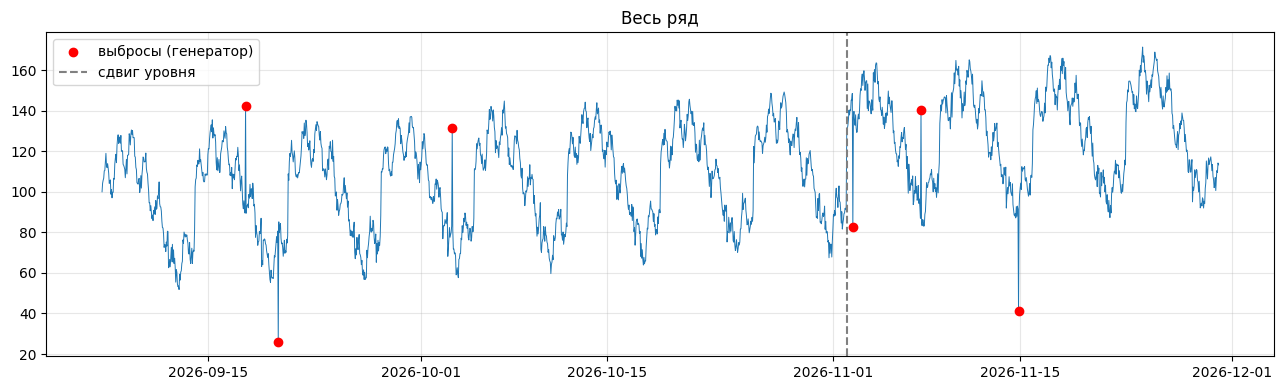

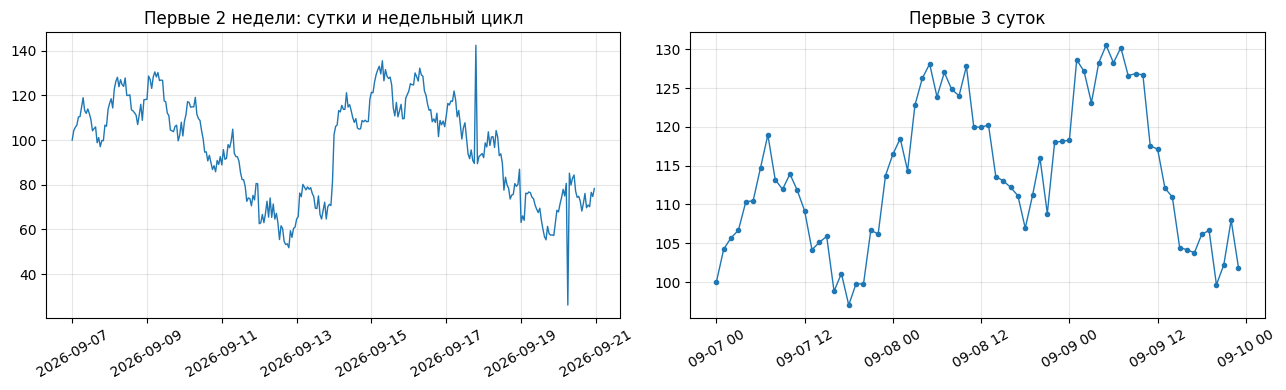

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(y.index, y, lw=0.7)
ax.scatter(y.index[is_out], y[is_out], color="red", zorder=3, label="выбросы (генератор)")
ax.axvline(y.index[SHIFT_AT], color="gray", ls="--", label="сдвиг уровня")
ax.set_title("Весь ряд"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
a = y.iloc[:168 * 2]
axes[0].plot(a.index, a, lw=1); axes[0].set_title("Первые 2 недели: сутки и недельный цикл")
b = y.iloc[:72]
axes[1].plot(b.index, b, marker=".", lw=1); axes[1].set_title("Первые 3 суток")
for ax in axes:
    ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); plt.show()

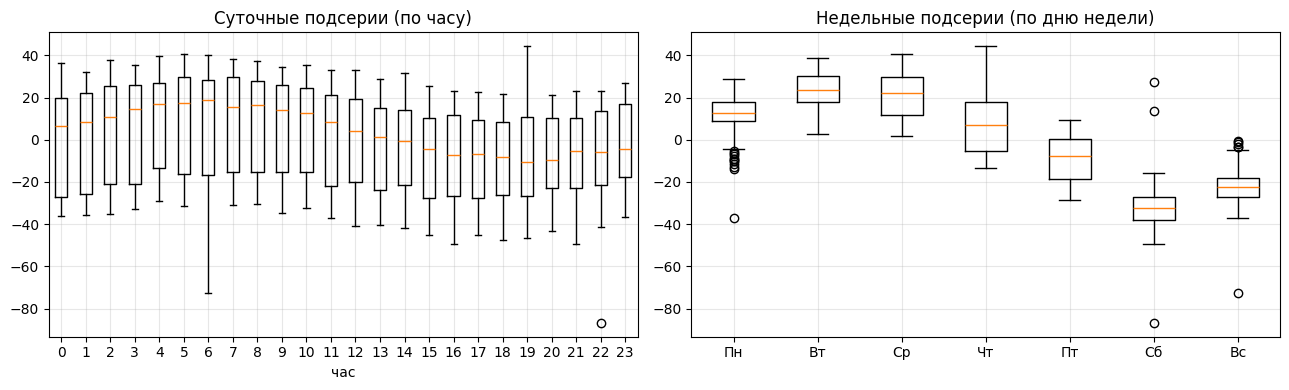

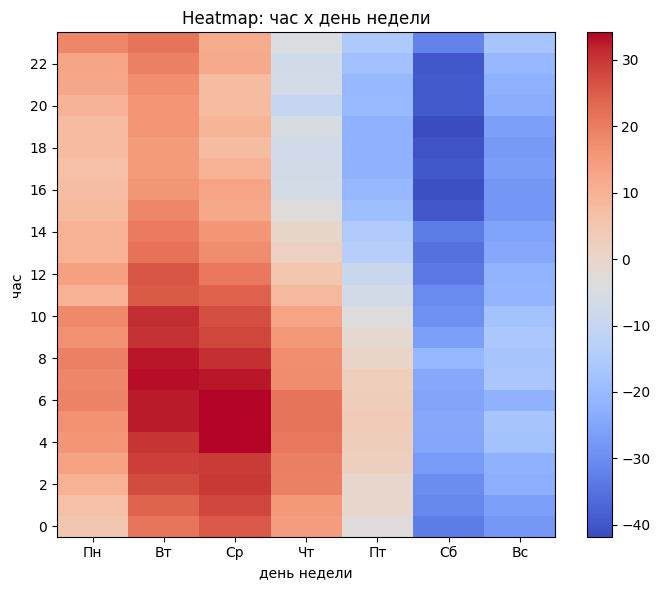

In [ ]:
# подсерии: убираем медленную часть (скользящее среднее за неделю не трогает недельный цикл: окно = его период)
detr = y - y.rolling(168, center=True, min_periods=84).mean()
DOW = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_hour = [g.dropna().to_numpy() for _, g in detr.groupby(y.index.hour)]
by_dow = [g.dropna().to_numpy() for _, g in detr.groupby(y.index.dayofweek)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot(by_hour); axes[0].set_xticks(range(1, 25)); axes[0].set_xticklabels(range(24))
axes[0].set_title("Суточные подсерии (по часу)"); axes[0].set_xlabel("час")
axes[1].boxplot(by_dow); axes[1].set_xticks(range(1, 8)); axes[1].set_xticklabels(DOW)
axes[1].set_title("Недельные подсерии (по дню недели)")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

heat = (pd.DataFrame({"v": detr.to_numpy(), "hour": y.index.hour, "dow": y.index.dayofweek})
        .pivot_table(index="hour", columns="dow", values="v", aggfunc="mean"))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="coolwarm", origin="lower")
ax.set_xticks(range(7)); ax.set_xticklabels(DOW)
ax.set_yticks(range(0, 24, 2)); ax.set_yticklabels(range(0, 24, 2))
ax.set_xlabel("день недели"); ax.set_ylabel("час"); ax.set_title("Heatmap: час x день недели")
fig.colorbar(im); fig.tight_layout(); plt.show()

## 3. Шаг 2. ACF исходного ряда

Чтобы тренд не заглушил пики, сначала вычитаем линейный тренд (`np.polyfit`, степень 1). Автокорреляция на лаге $k$:

$$r_k = \frac{\sum_{t=k+1}^{n}(x_t-\bar x)(x_{t-k}-\bar x)}{\sum_{t=1}^{n}(x_t-\bar x)^2}$$

Граница значимости на уровне 95%: $\pm 1{,}96/\sqrt n$.

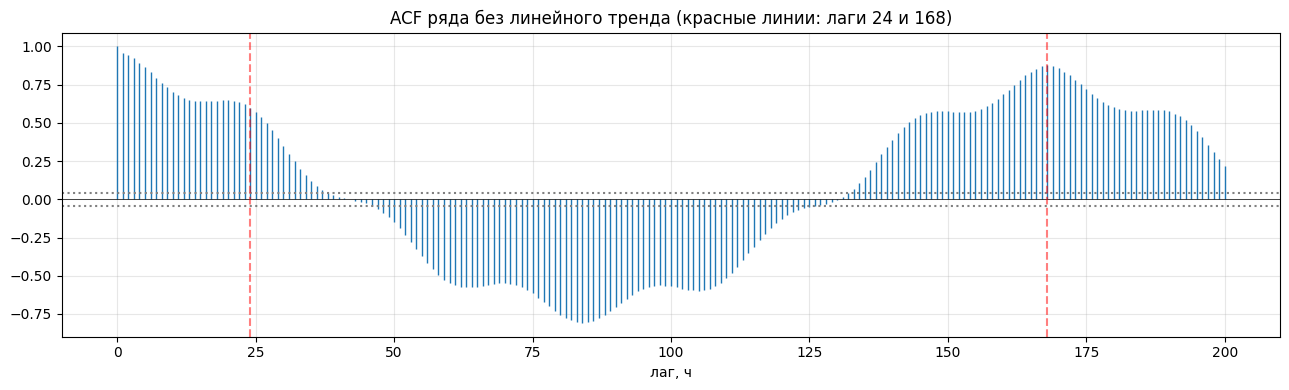

граница значимости = 1.96 / sqrt(2016) = 0.0437
r_12  = 697,493 / 1,050,411 = 0.664
r_24  = 629,722 / 1,050,411 = 0.599
r_48  = -93,070 / 1,050,411 = -0.089
r_168 = 922,136 / 1,050,411 = 0.878
r_336 = 833,711 / 1,050,411 = 0.794


In [ ]:
def acf_manual(x, k):
    x = np.asarray(x, float); d = x - x.mean()
    num = float((d[k:] * d[:-k]).sum()); den = float((d * d).sum())
    return num, den, num / den


def plot_acf_own(ax, x, title, nlags=200):
    r = acf(np.asarray(x, float), nlags=nlags, fft=True)
    ax.vlines(range(len(r)), 0, r, lw=1)
    ax.axhline(0, color="k", lw=0.5)
    bound = 1.96 / np.sqrt(len(x))
    ax.axhline(bound, color="gray", ls=":"); ax.axhline(-bound, color="gray", ls=":")
    for L in (24, 168):
        ax.axvline(L, color="red", ls="--", alpha=0.5)
    ax.set_title(title); ax.set_xlabel("лаг, ч"); ax.grid(alpha=0.3)


t = np.arange(N)
coef = np.polyfit(t, y.to_numpy(), 1)
y_lin = y.to_numpy() - np.polyval(coef, t)

fig, ax = plt.subplots(figsize=(13, 4))
plot_acf_own(ax, y_lin, "ACF ряда без линейного тренда (красные линии: лаги 24 и 168)")
fig.tight_layout(); plt.show()

print(f"граница значимости = 1.96 / sqrt({N}) = {1.96 / np.sqrt(N):.4f}")
for L in (12, 24, 48, 168, 336):
    num, den, r = acf_manual(y_lin, L)
    print(f"r_{L:<3} = {num:,.0f} / {den:,.0f} = {r:.3f}")

## 4. Шаги 3–5. Три разложения

Во всех трёх вызовах аддитивная модель $y_t = T_t + S_t + R_t$ (для MSTL: $y_t = T_t + S^{(24)}_t + S^{(168)}_t + R_t$).

- **Классическая**: `seasonal_decompose(period=24)`. Тренд — скользящее среднее длины 24, сезонность — средние по часам суток.
- **STL**: `STL(period=24, robust=True)`. Тренд и сезонность сглаживаются локальной регрессией (LOESS), `robust=True` ослабляет влияние выбросов.
- **MSTL**: `MSTL(periods=(24, 168), stl_kwargs={"robust": True})`. Сезонности выделяются по очереди, каждая своим STL.

In [ ]:
cls = seasonal_decompose(y, model="additive", period=24)
stl = STL(y, period=24, robust=True).fit()
mstl = MSTL(y, periods=(24, 168), stl_kwargs={"robust": True}).fit()

results = {
    "Классическая (24)": dict(trend=cls.trend, seasonal={"24": cls.seasonal}, resid=cls.resid),
    "STL (24, robust)": dict(trend=stl.trend, seasonal={"24": stl.seasonal}, resid=stl.resid),
    "MSTL (24+168, robust)": dict(trend=mstl.trend,
                                  seasonal={"24": mstl.seasonal["seasonal_24"], "168": mstl.seasonal["seasonal_168"]},
                                  resid=mstl.resid),
}
for name, r in results.items():
    print(f"{name:24s} NaN в тренде: {int(r['trend'].isna().sum()):3d} | NaN в остатке: {int(r['resid'].isna().sum()):3d}")

Классическая (24)        NaN в тренде:  24 | NaN в остатке:  24
STL (24, robust)         NaN в тренде:   0 | NaN в остатке:   0
MSTL (24+168, robust)    NaN в тренде:   0 | NaN в остатке:   0


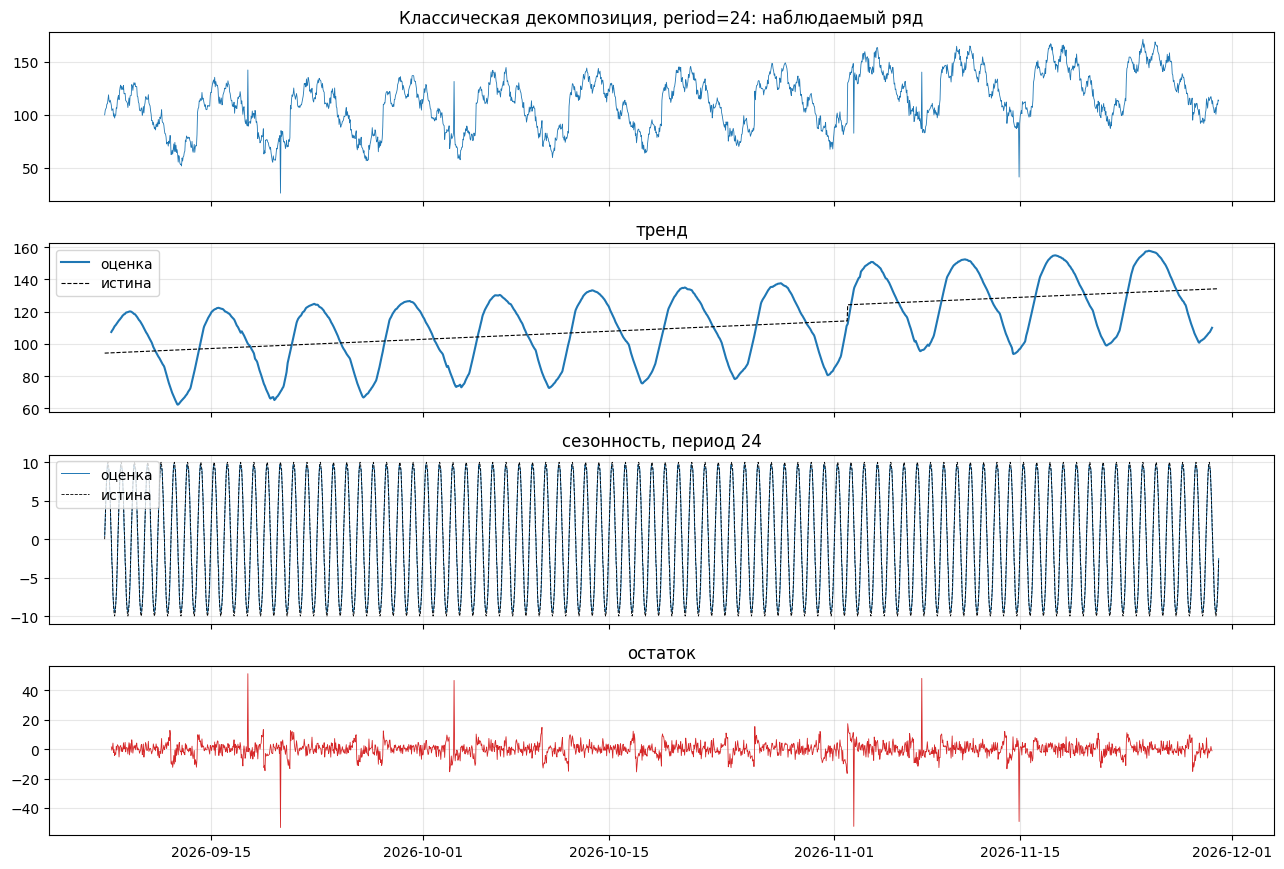

In [ ]:
truth_sets = {"24": true_daily, "168": true_weekly}


def plot_decomp(name, res):
    n_s = len(res["seasonal"])
    fig, axes = plt.subplots(n_s + 3, 1, figsize=(13, 2.2 * (n_s + 3)), sharex=True)
    axes[0].plot(y.index, y, lw=0.6); axes[0].set_title(f"{name}: наблюдаемый ряд")
    axes[1].plot(y.index, res["trend"], label="оценка"); axes[1].plot(y.index, true_trend, "--", color="k", lw=0.8, label="истина")
    axes[1].set_title("тренд"); axes[1].legend(loc="upper left")
    for k, (p, s) in enumerate(res["seasonal"].items()):
        ax = axes[2 + k]
        ax.plot(y.index, s, lw=0.7, label="оценка"); ax.plot(y.index, truth_sets[p], "--", color="k", lw=0.6, label="истина")
        ax.set_title(f"сезонность, период {p}"); ax.legend(loc="upper left")
    axes[-1].plot(y.index, res["resid"], lw=0.6, color="C3"); axes[-1].set_title("остаток")
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.tight_layout(); plt.show()


plot_decomp("Классическая декомпозиция, period=24", results["Классическая (24)"])

In [ ]:
plot_decomp("STL, period=24, robust=True", results["STL (24, robust)"])

In [ ]:
plot_decomp("MSTL, periods=(24, 168), robust=True", results["MSTL (24+168, robust)"])

## 5. Шаг 6. Количественное сравнение

Что считаем (для каждого метода):

- **дисперсию остатка** $\mathrm{Var}=\sum(r_t-\bar r)^2/(n-1)$: по всем точкам, без 6 выбросов и робастную $(1{,}4826\cdot \mathrm{MAD})^2$. Заложенная дисперсия шума равна $3^2=9$, это ориентир «чистого» остатка;
- **ACF остатка на лагах 24 и 168** (6 выбросов заменены медианой остатка, иначе они доминируют в знаменателе $r_k$ у всех методов);
- **утечку недельной компоненты**: корреляцию истинной недельной компоненты с ошибкой тренда `(тренд − истинный тренд)` и с остатком. Если недельный цикл не выделен, он оказывается либо в тренде, либо в остатке;
- **RMSE компонент** относительно истинных (для метода без недельной компоненты она считается нулём).

In [ ]:
def rmse(a, b, mask):
    return float(np.sqrt(np.mean((np.asarray(a)[mask] - np.asarray(b)[mask]) ** 2)))


rows, details = [], {}
for name, res in results.items():
    r = res["resid"]
    ok = r.notna().to_numpy() & res["trend"].notna().to_numpy()      # у классической NaN по краям
    r_ok = r.to_numpy()[ok]
    n_ok = int(ok.sum())
    ss = float(((r_ok - r_ok.mean()) ** 2).sum())
    var_all = ss / (n_ok - 1)
    keep = ok & ~is_out
    var_no = float(np.var(r.to_numpy()[keep], ddof=1))
    mad = float(np.median(np.abs(r_ok - np.median(r_ok))))
    var_rob = (1.4826 * mad) ** 2
    details[name] = (n_ok, ss, var_all)

    rc = r_ok.copy()
    rc[np.flatnonzero(is_out[ok])] = np.median(r_ok)   # выбросы -> медиана, только для ACF
    a24 = acf_manual(rc, 24)[2]; a168 = acf_manual(rc, 168)[2]

    leak_tr = np.corrcoef((res["trend"].to_numpy() - true_trend)[ok], true_weekly[ok])[0, 1]
    leak_res = np.corrcoef(r.to_numpy()[keep], true_weekly[keep])[0, 1]

    rm_d = rmse(res["seasonal"]["24"], true_daily, ok)
    rm_w = rmse(res["seasonal"]["168"], true_weekly, ok) if "168" in res["seasonal"] else rmse(np.zeros(N), true_weekly, ok)
    rm_t = rmse(res["trend"], true_trend, ok)
    rows.append({"метод": name, "Var остатка": var_all, "Var без выбросов": var_no, "Var робаст.": var_rob,
                 "ACF(24)": a24, "ACF(168)": a168,
                 "утечка недели в тренд": leak_tr, "утечка недели в остаток": leak_res,
                 "RMSE суточной": rm_d, "RMSE недельной": rm_w, "RMSE тренда": rm_t})

table = pd.DataFrame(rows).set_index("метод")
display(table.round(3).T)

print(f"\nграница значимости ACF для n = 2016: 1.96 / sqrt(2016) = {1.96 / np.sqrt(2016):.4f}")
print("Дисперсия остатка (формула Var = SS / (n - 1)):")
for name, (n_ok, ss, v) in details.items():
    print(f"  {name:24s} Var = {ss:,.1f} / ({n_ok} - 1) = {v:.2f}")
base_v, m_v = table.iloc[0]["Var без выбросов"], table.iloc[2]["Var без выбросов"]
print(f"\nVar без выбросов: классическая / MSTL = {base_v:.2f} / {m_v:.2f} = {base_v / m_v:.2f} раза; "
      f"заложенный шум = {NOISE_STD ** 2:.1f}")

метод,Классическая (24),"STL (24, robust)","MSTL (24+168, robust)"
Var остатка,26.374,29.974,15.455
Var без выбросов,18.827,22.452,7.338
Var робаст.,13.869,9.555,3.798
ACF(24),0.018,-0.006,-0.075
ACF(168),0.472,0.578,-0.110
утечка недели в тренд,0.988,0.985,-0.225
утечка недели в остаток,0.289,0.536,0.032
RMSE суточной,0.548,1.831,1.301
RMSE недельной,21.025,20.966,1.443
RMSE тренда,20.027,18.667,0.986



граница значимости ACF для n = 2016: 1.96 / sqrt(2016) = 0.0437
Дисперсия остатка (формула Var = SS / (n - 1)):
  Классическая (24)        Var = 52,511.0 / (1992 - 1) = 26.37
  STL (24, robust)         Var = 60,398.2 / (2016 - 1) = 29.97
  MSTL (24+168, robust)    Var = 31,141.7 / (2016 - 1) = 15.45

Var без выбросов: классическая / MSTL = 18.83 / 7.34 = 2.57 раза; заложенный шум = 9.0


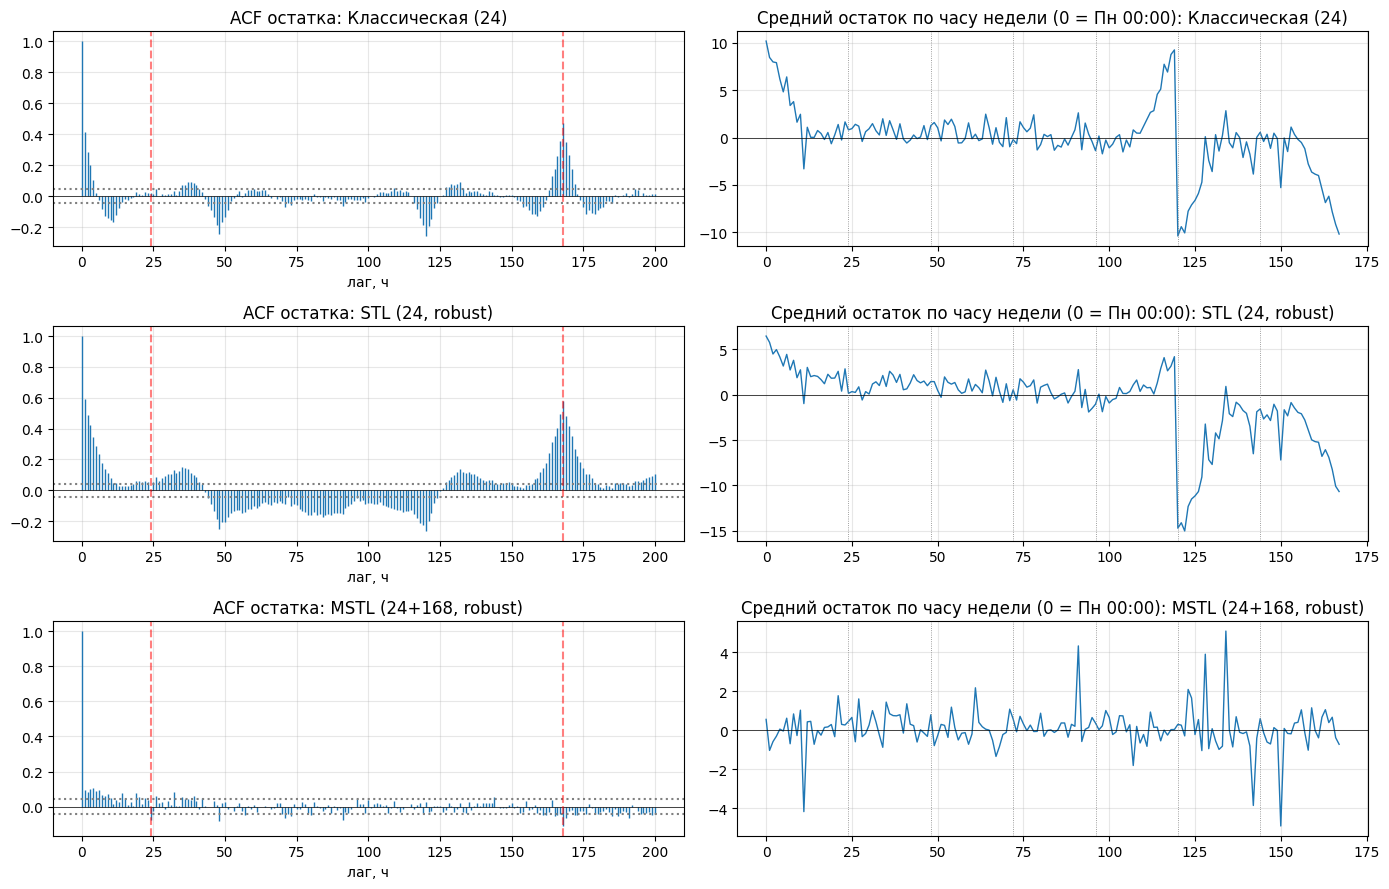

In [ ]:
# ACF остатков (выбросы заменены медианой) и недельный профиль остатка
how = (y.index.dayofweek * 24 + y.index.hour).to_numpy()
fig, axes = plt.subplots(3, 2, figsize=(14, 9))
for row, (name, res) in enumerate(results.items()):
    r = res["resid"]; ok = r.notna().to_numpy()
    rv = r.to_numpy().copy(); rv[is_out] = np.nan
    rv = pd.Series(rv).fillna(np.nanmedian(rv)).to_numpy()[ok]
    plot_acf_own(axes[row, 0], rv, f"ACF остатка: {name}")
    prof = pd.Series(r.to_numpy()).groupby(how).mean()
    axes[row, 1].plot(prof.index, prof.values, lw=1)
    axes[row, 1].axhline(0, color="k", lw=0.5); axes[row, 1].grid(alpha=0.3)
    for d in range(1, 7):
        axes[row, 1].axvline(24 * d, color="gray", ls=":", lw=0.6)
    axes[row, 1].set_title(f"Средний остаток по часу недели (0 = Пн 00:00): {name}")
fig.tight_layout(); plt.show()

## 6. Шаг 7. Интерпретация компонент MSTL

Какая компонента что описывает и как выглядит тренд после удаления обеих сезонностей.

Суточная (период 24):
  максимум в 5:00, минимум в 18:00
  амплитуда = (макс - мин) / 2 = (10.03 - (-9.86)) / 2 = 9.95  (заложено: 10)

Недельная (период 168):
  будни минус выходные (оценка) = 11.32 - (-28.34) = 39.66
  то же по истинной компоненте  = 11.24 - (-28.11) = 39.35

Тренд (после удаления обеих сезонностей):
  наклон = (среднее нед.7 - среднее нед.1) / расстояние = 0.0164 ед./ч  (заложено: 30 / 2015 = 0.0149)
  сдвиг уровня = (после - до) - наклон * расстояние = (124.47 - 114.11) - 0.0164 * 192 = 7.21  (заложено: 10.0)


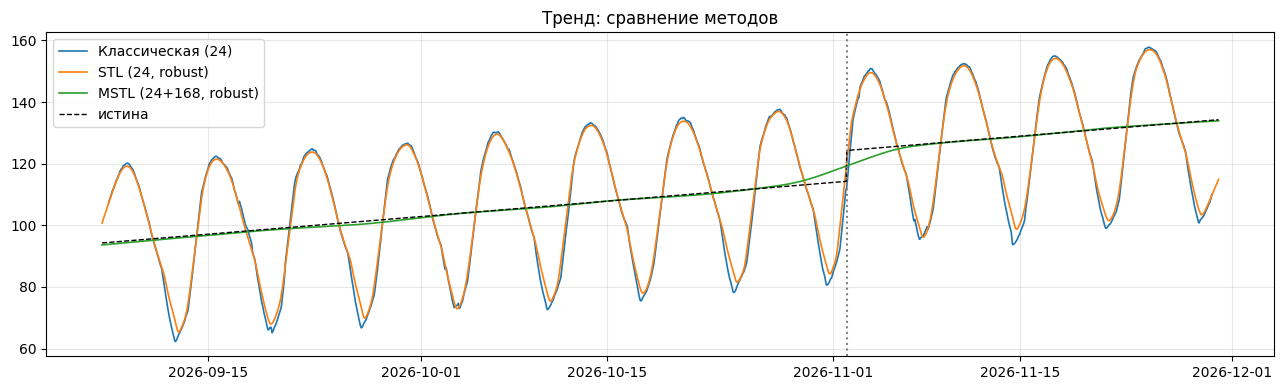

In [ ]:
m = results["MSTL (24+168, robust)"]
s24, s168, tr = m["seasonal"]["24"], m["seasonal"]["168"], m["trend"]

# суточная компонента: средний профиль по часу
prof24 = s24.groupby(y.index.hour).mean()
amp24 = (prof24.max() - prof24.min()) / 2
print("Суточная (период 24):")
print(f"  максимум в {int(prof24.idxmax())}:00, минимум в {int(prof24.idxmin())}:00")
print(f"  амплитуда = (макс - мин) / 2 = ({prof24.max():.2f} - ({prof24.min():.2f})) / 2 = {amp24:.2f}  (заложено: 10)")

# недельная компонента: будни против выходных
wk_est = s168.groupby(y.index.dayofweek).mean()
d_est = wk_est.loc[0:4].mean() - wk_est.loc[5:6].mean()
tw = pd.Series(true_weekly).groupby(y.index.dayofweek).mean()
d_true = tw.loc[0:4].mean() - tw.loc[5:6].mean()
print("\nНедельная (период 168):")
print(f"  будни минус выходные (оценка) = {wk_est.loc[0:4].mean():.2f} - ({wk_est.loc[5:6].mean():.2f}) = {d_est:.2f}")
print(f"  то же по истинной компоненте  = {tw.loc[0:4].mean():.2f} - ({tw.loc[5:6].mean():.2f}) = {d_true:.2f}")

# тренд: наклон и сдвиг уровня
slope = (tr.iloc[SHIFT_AT - 24 * 7: SHIFT_AT - 24].mean() - tr.iloc[24: 24 * 7].mean()) / (SHIFT_AT - 24 * 7 - 24)
slope_true = 30.0 / (N - 1)
before = tr.iloc[SHIFT_AT - 168: SHIFT_AT - 24].mean()
after = tr.iloc[SHIFT_AT + 24: SHIFT_AT + 168].mean()
dist = ((SHIFT_AT + 24) + (SHIFT_AT + 168)) / 2 - ((SHIFT_AT - 168) + (SHIFT_AT - 24)) / 2   # между серединами окон = 192 ч
jump = (after - before) - slope * dist
print("\nТренд (после удаления обеих сезонностей):")
print(f"  наклон = (среднее нед.7 - среднее нед.1) / расстояние = {slope:.4f} ед./ч  (заложено: 30 / {N - 1} = {slope_true:.4f})")
print(f"  сдвиг уровня = (после - до) - наклон * расстояние = ({after:.2f} - {before:.2f}) - {slope:.4f} * {dist:.0f} = {jump:.2f}  (заложено: {SHIFT})")

fig, ax = plt.subplots(figsize=(13, 4))
for name, res in results.items():
    ax.plot(y.index, res["trend"], lw=1.2, label=name)
ax.plot(y.index, true_trend, "k--", lw=1, label="истина")
ax.axvline(y.index[SHIFT_AT], color="gray", ls=":")
ax.set_title("Тренд: сравнение методов"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); plt.show()

## 7. Шаг 8. Выводы

Ряд: почасовой синтетический, 2 016 точек (12 недель), суточная (24) и недельная (168) сезонность, тренд, сдвиг уровня и 6 выбросов. Заложенная дисперсия шума 3² = 9.

## 1. ACF подтверждает обе сезонности

Граница значимости: 1,96/√2016 = 0,0437. На лагах 24 и 168 автокорреляция намного выше неё:

- r₂₄ = 629 722 / 1 050 411 = 0,599
- r₁₆₈ = 922 136 / 1 050 411 = 0,878
- на втором недельном лаге r₃₃₆ = 833 711 / 1 050 411 = 0,794

Пик на 168 выражен сильнее: недельная компонента крупнее суточной (амплитуда 20 против 10 плюс выходные). Лаг 24 на графике скорее «плечо», чем отдельный пик: r₁₂ = 0,664 даже выше r₂₄. Поэтому суточную сезонность стоит подкреплять подсериями и heatmap, а не одним ACF.

## 2. Классика и STL с period=24 не выделяют недельный цикл

Недельный цикл остаётся в тренде и в остатке.

- Корреляция ошибки тренда с истинной недельной компонентой: 0,988 (классика) и 0,985 (STL). На графике трендов видно, что их тренды волнистые, с недельной волной.
- В остатке недельная структура тоже есть: ACF(168) = 0,472 (классика) и 0,578 (STL) при границе 0,0437. Средний остаток по часу недели скачет примерно на ±10 на границе выходных (около часа 120, пятница → суббота).
- RMSE тренда 20,03 и 18,67, RMSE недельной компоненты 21,03 и 20,97. Недельной компоненты у этих методов нет, поэтому её ошибка равна размаху самой истинной недельной компоненты.

## 3. MSTL выделяет обе сезонности, остаток заметно чище

- Дисперсия остатка без выбросов: 18,83 (классика), 22,45 (STL), 7,34 (MSTL). Классика / MSTL = 18,83 / 7,34 = 2,57 раза, STL / MSTL = 22,45 / 7,34 = 3,06 раза. Заложенный шум 3² = 9, то есть MSTL ниже ориентира (7,34 / 9 = 0,82): часть шума сглаживание «съело» в компоненты.
- Структура в остатке убрана: ACF(168) = −0,110 против 0,472 и 0,578, график среднего остатка по часу недели плоский. Единичные всплески до ±5 это оставшиеся выбросы.
- Ошибки компонент: недельная 1,44 против \~21, тренд 0,99 против 20,03 и 18,67 (примерно в 20 раз меньше, чем у классики: 20,03 / 0,99 ≈ 20).
- Небольшие отрицательные значения ACF(168) = −0,110 и ACF(24) = −0,075 означают лёгкую «пересверку» сезонных компонент.

## 4. Интерпретация компонент MSTL

- **Период 24: суточный профиль.** Амплитуда (10,03 − (−9,86)) / 2 = 9,95 при заложенных 10. Максимум в 5:00 вместо теоретических 6:00: соседние часы отличаются меньше, чем шум.
- **Период 168: недельный профиль.** Будни минус выходные = 11,32 − (−28,34) = 39,66 против истинных 11,24 − (−28,11) = 39,35.
- **Тренд после удаления обеих сезонностей** это гладкая линия с наклоном 0,0164 ед./ч (заложено 30 / 2015 = 0,0149). Сдвиг уровня: (124,47 − 114,11) − 0,0164 · 192 = 7,21 вместо 10. Ступенька размазана окном LOESS на 1–2 недели (видно на графике около 1 ноября). Даже с истинным наклоном получилось бы 10,36 − 0,0149 · 192 = 7,50, то есть недооценка в основном из-за сглаживания.

## 5. Когда какой метод нужен

- **Классики достаточно** для одной устойчивой сезонности и чистых данных, как быстрая базовая оценка.
- **STL нужен** при выбросах и меняющейся форме сезонности. Эффект робастности виден по робастной дисперсии: 9,56 у STL против 13,87 у классики.
- **MSTL обязателен**, когда периодов несколько (24 и 168): иначе вторая сезонность попадает в тренд и остаток и портит интерпретацию и последующие модели.
- Все три метода размазывают сдвиг уровня: его ищут отдельными методами.